# 01 · Data Quality Audit

**Question:** Can the raw Olist data be trusted as-is? What has to be fixed before analysis?

**Method:** Profile the 9 raw tables, apply the cleaning rules in `src/ecom/clean.py`, and check the
result against data contracts (`src/ecom/validate.py`) and SQL tests (`sql/tests/`).
The full audit trail is generated on every pipeline run: [`reports/data_quality_report.md`](../reports/data_quality_report.md).

> Principle: **never invent data.** Unknown values stay missing and get a flag column, so each analysis can decide how to treat them.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ecom import viz

viz.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

In [ ]:
from ecom.ingest import load_all
from ecom.pipeline import clean_all
from ecom.quality import CleaningLog

raw = load_all()
audit = CleaningLog()
clean = clean_all(raw, audit)

pd.DataFrame(
    {
        "rows": {k: len(v) for k, v in raw.items()},
        "columns": {k: v.shape[1] for k, v in raw.items()},
    }
).sort_values("rows", ascending=False)

,rows,columns
geolocation,1000163,5
order_items,112650,7
payments,103886,5
customers,99441,5
orders,99441,8
reviews,99224,7
products,32951,9
sellers,3095,4
category_translation,71,2


## 1. Where is data missing, and is it random?

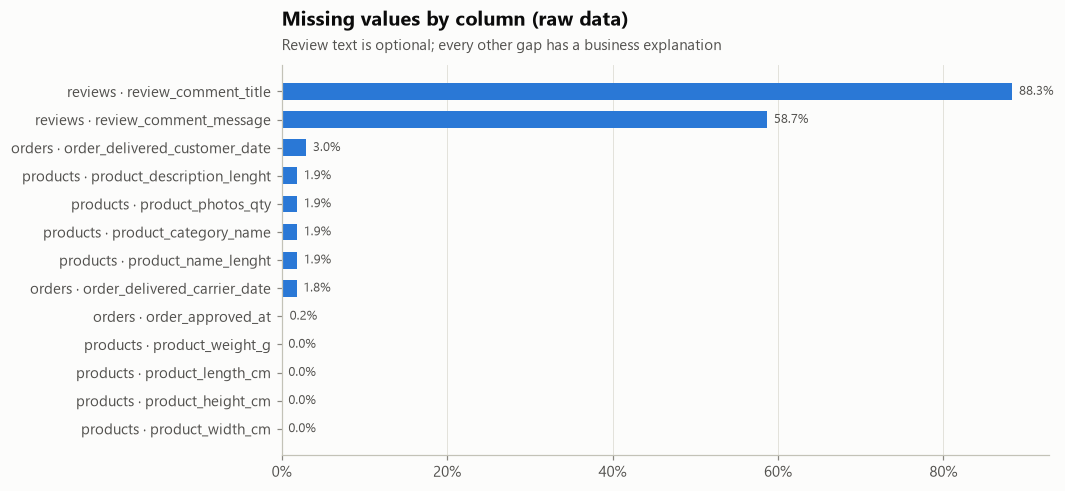

In [ ]:
missing = (
    pd.concat({name: df.isna().mean() * 100 for name, df in raw.items()})
    .rename("pct_missing")
    .reset_index()
    .rename(columns={"level_0": "table", "level_1": "column"})
    .query("pct_missing > 0")
    .sort_values("pct_missing")
)
missing["label"] = missing["table"] + " · " + missing["column"]

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(missing["label"], missing["pct_missing"], color=viz.BLUE, height=0.6)
for y, v in enumerate(missing["pct_missing"]):
    ax.text(v + 0.8, y, f"{v:.1f}%", va="center", fontsize=8.5, color=viz.INK_2)
ax.xaxis.set_major_formatter(viz.PCT)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Missing values by column (raw data)")
viz.subtitle(ax, "Review text is optional; every other gap has a business explanation")
plt.show()

In [ ]:
orders = raw["orders"]
pd.crosstab(
    orders["order_status"],
    orders["order_delivered_customer_date"]
    .isna()
    .map({True: "no delivery date", False: "has delivery date"}),
)

order_delivered_customer_date,has delivery date,no delivery date
order_status,,
approved,0,2
canceled,6,619
created,0,5
delivered,96470,8
invoiced,0,314
processing,0,301
shipped,0,1107
unavailable,0,609


**Finding:** the missingness is *structural*, not random:

- **Delivery dates** are missing because the order never arrived (shipped / canceled / unavailable),
  except for **8 "delivered" orders with no date**, which are flagged as anomalies.
- **Product attributes**: the same 610 products miss category, name length, description length and photo count together.
  This is one upstream catalogue gap, so they are labelled `unknown` instead of being imputed.
- **Review comments** are optional free text (58% empty). Filling them with "No Comment" (as the first version of this project did)
  would add fake text, so they stay NA with a `has_comment` flag.

## 2. Every cleaning rule, with rows affected

In [ ]:
audit.to_frame()

,table,rule,rows_affected,action
0,customers,"customer_id is per-order; 96,096 real people (...",3345,info
1,sellers,normalised zip / city / state,3095,fixed
2,orders,status 'delivered' but no delivery timestamp,8,flagged
3,orders,status 'canceled' but has delivery timestamp,6,flagged
4,orders,handed to carrier before payment approval (tim...,1359,flagged
5,orders,derived delivery_days / delivery_delay_days / ...,99441,derived
6,orders,outside analysis window 2017-01-01 to 2018-09-...,349,flagged
7,orders,duplicate order_id,0,dropped
8,order_items,derived item_total = price + freight_value,112650,derived
9,order_items,"zero freight (free shipping), kept as valid",383,info


## 3. Choosing the analysis window

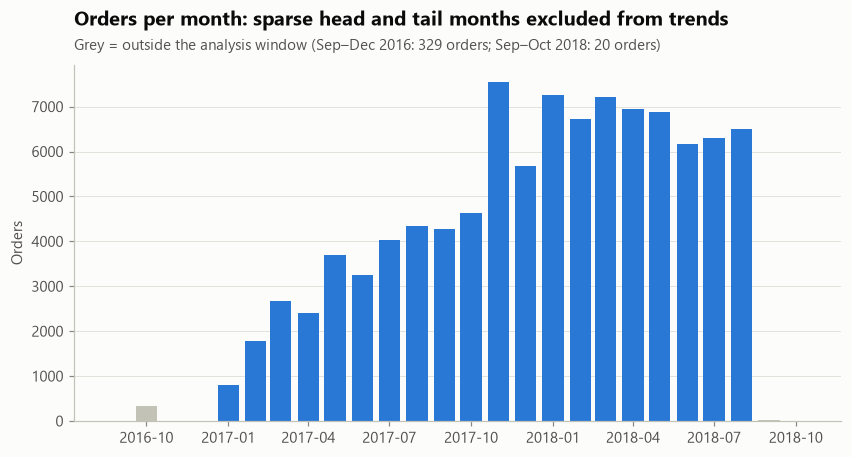

In [ ]:
monthly = (
    clean["orders"]
    .groupby("purchase_month")
    .agg(orders=("order_id", "size"), in_window=("in_analysis_window", "first"))
    .reset_index()
)
fig, ax = plt.subplots()
colors = np.where(monthly["in_window"], viz.BLUE, viz.NEUTRAL)
ax.bar(monthly["purchase_month"], monthly["orders"], width=24, color=colors)
ax.set_title("Orders per month: sparse head and tail months excluded from trends")
viz.subtitle(
    ax, "Grey = outside the analysis window (Sep–Dec 2016: 329 orders; Sep–Oct 2018: 20 orders)"
)
ax.set_ylabel("Orders")
viz.save(fig, "analysis_window")
plt.show()

Sep–Dec 2016 is a launch period (November 2016 has **zero** orders), and Sep–Oct 2018 contains just 20 orders,
an extraction cut-off. Including them would create a fake "collapse" at the end of every trend line and wreck the forecasts.
Rows are **kept** in the warehouse but flagged `in_analysis_window = false`.

## 4. The customer ID trap

In [ ]:
c = raw["customers"]
print(f"customer_id values:        {c['customer_id'].nunique():,}")
print(f"customer_unique_id values: {c['customer_unique_id'].nunique():,}")
print(f"orders:                    {raw['orders']['order_id'].nunique():,}")

customer_id values:        99,441
customer_unique_id values: 96,096
orders:                    99,441


`customer_id` is generated **per order** (99,441 IDs = 99,441 orders), so counting it makes every customer look like a first-time buyer.
The real person is `customer_unique_id` (**96,096**). All customer metrics in this project use it.

## 5. Validation result

In [ ]:
from ecom.validate import validate_all

pd.Series(validate_all(clean), name="result").to_frame()

,result
schema:customers,passed
schema:sellers,passed
schema:orders,passed
schema:order_items,passed
schema:payments,passed
schema:products,passed
schema:reviews,passed
schema:geolocation,passed
fk:orders.customer_id -> customers.customer_id,passed
fk:order_items.order_id -> orders.order_id,passed


## Conclusion

| Before | After |
|---|---|
| Hard-coded paths, manual MySQL load | One command rebuilds everything (`.\tasks.ps1 pipeline`) |
| Fake zeros for weights; "No Comment" and 0-star placeholders | NA plus flag columns; no invented values |
| Portuguese category names; 2 missing from the translation file | English names, gaps mapped manually |
| `customer_id` used as the customer | `customer_unique_id` (96,096 people) |
| Revenue mixed canceled orders with freight-less item prices | One revenue definition ([`docs/metrics.md`](../docs/metrics.md)), reconciled by SQL tests |
| No checks | 8 pandera contracts, 6 FK checks, 8 SQL data tests; the pipeline fails loudly |